
<h1 align="center"> CSE 242 Assignment 2



<h2 align="center"> 3 Questions, 100 pts
    
    Your name: Julian Lucas          Student ID: 1853846

Claude code used for  the plotting code, the LaTeX for Q1, code for 3.1, 3.2 and 3.4, and feedback on written answers.

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estimation (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estimation and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a)**:




$$L(h) = h^3 (1-h)^2$$

Take the log

$$\ell(h) = \log L(h) = 3\log h + 2\log(1-h)$$

Take the derivative, set it to zero:

$$\frac{d\ell}{dh} = \frac{3}{h} - \frac{2}{1-h} = 0$$

Solve:

$$\begin{aligned}
\frac{3}{h} &= \frac{2}{1-h} \\
3(1-h) &= 2h \\
3 &= 5h \\
\hat{h}_{\text{MLE}} &= \frac{3}{5} = 0.6
\end{aligned}$$

Which is what we'd get if we just took the count of heads.


**Solution (b)**:

We want $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$

Bayes Rule says:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

So we can write it as:

$$p(h \mid \mathbf{HHHTT}) = \frac{P(\mathbf{HHHTT} \mid h)\, p(h)}{P(\mathbf{HHHTT})}$$

We know that:

$$P(\mathbf{HHHTT} \mid h) = h^3 (1-h)^2$$

We can write the denominator with t to avoid confusion:

$$P(\mathbf{HHHTT}) = \int_0^1 t^3 (1-t)^2\, p(t)\, dt$$

Which gives:

$$p(h \mid \mathbf{HHHTT}) = \frac{h^3 (1-h)^2\, p(h)}{\displaystyle\int_0^1 t^3 (1-t)^2\, p(t)\, dt}$$


# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Imports

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


from sklearn import metrics
from sklearn.metrics import root_mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

### Read in data

In [2]:
input_data_fp = 'Advertising.csv'
data = pd.read_csv(input_data_fp, index_col=0)

# Take a look at the first 5 rows
data.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [3]:
data.shape

(200, 4)

### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [4]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
(200, 3)


In [5]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.core.series.Series'>
(200,)


In [6]:
# Check for missing values
print("missing values:")
print(data.isna().sum())

missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


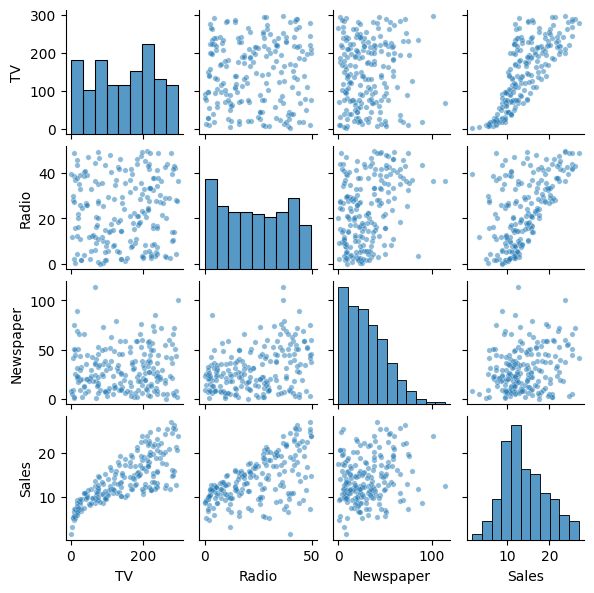

In [7]:
## Get a feel for the data
sns.pairplot(data, kind='scatter', plot_kws={'alpha': 0.5, 's': 15}, height=1.5)
plt.show()

## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [8]:
## pulled from:
## https://www.geeksforgeeks.org/machine-learning/how-to-do-train-test-split-using-sklearn-in-python/


# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Double check the shape of train and test data:

In [9]:
# default split is 80% for training and 20% for testing
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(160, 3)
(160,)
(40, 3)
(40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [10]:
## Pulled from
## https://www.geeksforgeeks.org/machine-learning/python-linear-regression-using-sklearn/

# Name your linear regression model as 'model', so proceeding cells won't run into errors.
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [11]:
print(f"Model intercept: {np.round(model.intercept_, 4)}\n")

print("Model coefficients:")
for val in model.coef_:
    print(f"{np.round(val, 4)}")

Model intercept: 2.9791

Model coefficients:
0.0447
0.1892
0.0028


In [12]:
# Match the feature names with the trained coefficients
list(zip(data.columns[:3].tolist(), model.coef_))

[('TV', np.float64(0.044729517468716326)),
 ('Radio', np.float64(0.18919505423437652)),
 ('Newspaper', np.float64(0.0027611143413671935))]

## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$$



- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

### Your solution for Question 2.3: 


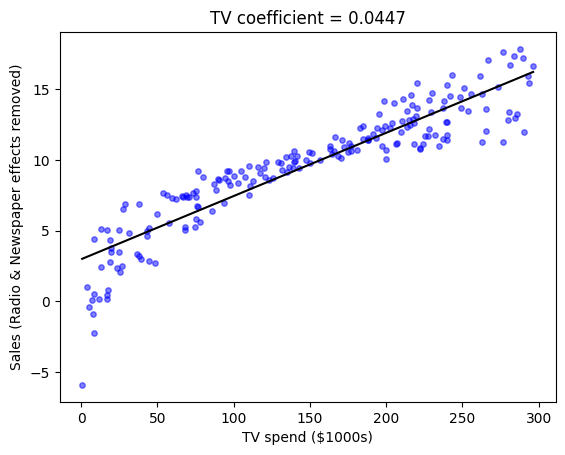

In [13]:
b_tv, b_radio, b_news = model.coef_

# Sales with the Radio and Newspaper contributions subtracted out
sales_adj = y - b_radio * X['Radio'] - b_news * X['Newspaper']

plt.scatter(X['TV'], sales_adj, color='b', alpha=0.5, s=15)

tv_range = np.array([X['TV'].min(), X['TV'].max()])
plt.plot(tv_range, model.intercept_ + b_tv * tv_range, color='k')

plt.xlabel('TV spend ($1000s)')
plt.ylabel('Sales (Radio & Newspaper effects removed)')
plt.title(f'TV coefficient = {b_tv:.4f}')
plt.show()

Trained linear regression model:
$$\text{Sales} = 2.9791 + 0.0447 \times \text{TV} + 0.1892 \times \text{Radio} + 0.0028 \times \text{Newspaper}$$


**Open Question Answer**: I read this as having two parts: 1. what is the meaning of the coefficient, and does this coefficient tell us much for this data.

The meaning of the coefficient is the slope of the best fit curve for (thousands of) dollars spent on TV advertising and sales (as thousands of units). So, for each additional thousand dollar spend on TV advertising, how many more (thousand) units do we expect to sell.

The coefficient for TV is not the largest, meaning that it may not be the most efficient way to spend advertising dollars. That being said, looking at the raw data (above) we can see that the relationship does look real.

It is also worth noting that the linearity assumption breaks down here at very low advertising dollars spent. That is probably ok for the linear regression as most of the data is in the linear part of the curve.

### Making predictions

In [14]:
# make predictions on the testing set
y_pred = model.predict(X_test)
# Print the test accuracy score from your trained linear regression model
model.score(X_test,y_test)

0.899438024100912

**Take a look at the predicted vs actual sales**

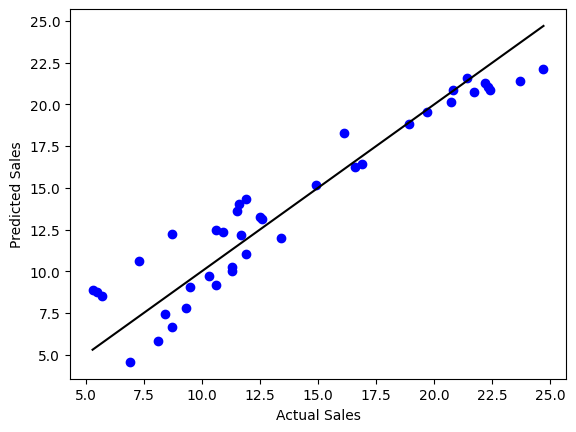

In [15]:
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='k')  # perfect-prediction line
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.show()

## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [16]:

################# Your answer for Question 2.4   #################
root_mean_squared_error(y_test, y_pred)

np.float64(1.78159966153345)

## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

**First check to see what the Newspaper only signal looks like**

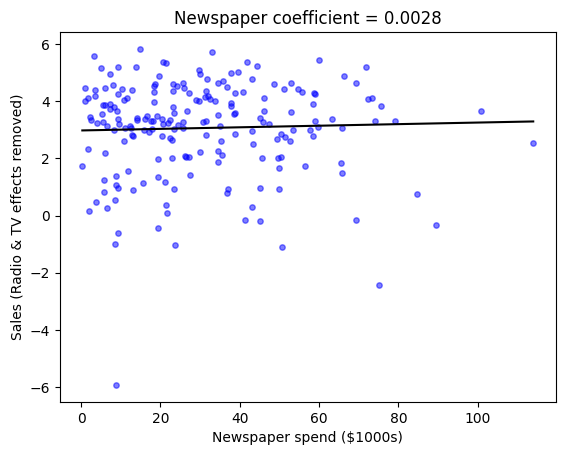

In [17]:
b_tv, b_radio, b_news = model.coef_

# Sales with the Radio and TV contributions subtracted out
sales_adj = y - b_radio * X['Radio'] - b_tv * X['TV']

plt.scatter(X['Newspaper'], sales_adj, color='b', alpha=0.5, s=15)

tv_range = np.array([X['Newspaper'].min(), X['Newspaper'].max()])
plt.plot(tv_range, model.intercept_ + b_news * tv_range, color='k')

plt.xlabel('Newspaper spend ($1000s)')
plt.ylabel('Sales (Radio & TV effects removed)')
plt.title(f'Newspaper coefficient = {b_news:.4f}')
plt.show()

**Now rerun the model with Newspaper removed**

In [18]:
X = data[['TV', 'Radio']]
y = data['Sales']

## Retrain
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Model intercept: {np.round(model.intercept_, 4)}\n")

print("Model coefficients:")
for val in model.coef_:
    print(f"{np.round(val, 4)}")


Model intercept: 3.0283

Model coefficients:
0.0447
0.1907


In [19]:
# make predictions on the testing set
y_pred = model.predict(X_test)
# Print the test accuracy score from your trained linear regression model
model.score(X_test,y_test)

0.9005833101920356

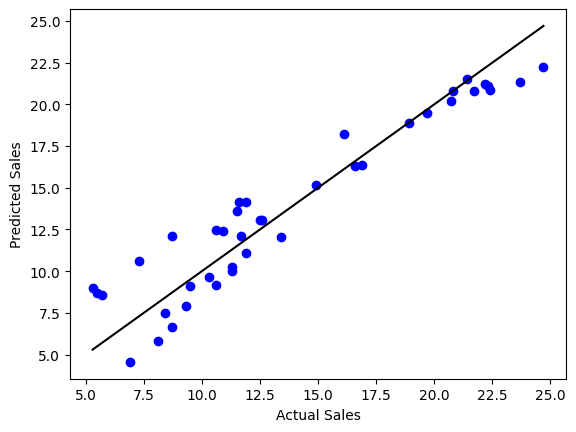

In [20]:
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='k')  # perfect-prediction line
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.show()

In [21]:
root_mean_squared_error(y_test, y_pred)

np.float64(1.7714254173033517)

### Your observations:
Newspaper didn't really predict anything in the original model. The coefficient was small and the data was spread roughly evenly. It's effect seems to be random noise.

RMSE before and after (below) removing Newspaper ad spend from the model is roughly the same, so it does not appear to be hindering the model.

TV + Radio + Newspaper = 1.7816 RMSE

TV + Radio = 1.7714 RMSE

# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [22]:
# import libraries
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; 
sns.set()

In [23]:
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

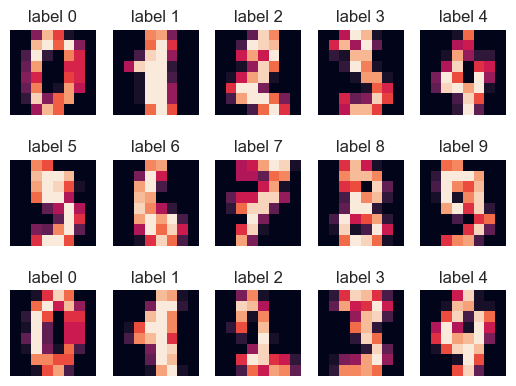

In [24]:
# A help function to display images with labels
def display_digits(imgs):
    h = 3
    w = 5
    fig, axes = plt.subplots(h, w)
    for i in range(h):
        for j in range(w):
            if imgs.shape[1] == 64:
                axes[i, j].imshow(imgs[i * w + j].reshape(8, 8))
            else:
                axes[i, j].imshow(imgs[i * w + j])
            axes[i, j].axis('off')
            axes[i, j].set_title(f'label {data_digit.target[i * w + j]}')
# Take a look at a few examples
display_digits(data_digit.images)

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [25]:
from sklearn.decomposition import PCA

################# Your answer for Question 3.1   #################

# name the transformed (dimension reduced) feature as projected
pca = PCA(n_components=2)
projected = pca.fit_transform(data_digit.data)


# The code below checks whether the feature dimension 64 is reduced to 2.
print(data_digit.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

/data/tmp/ipykernel_2747689/284023998.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('Paired', 10))


<Figure size 1800x800 with 0 Axes>

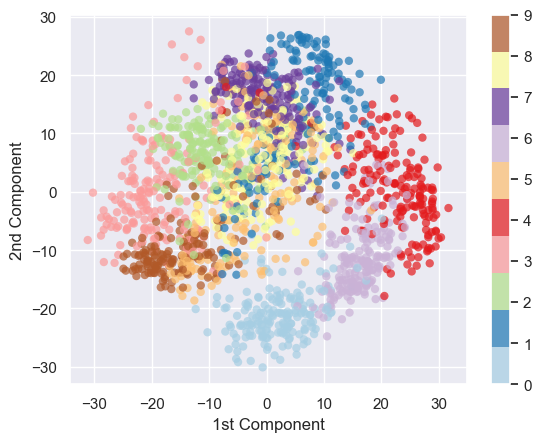

<Figure size 1800x800 with 0 Axes>

In [26]:
plt.scatter(projected[:, 0], projected[:, 1],
            c=data_digit.target, edgecolor='none', alpha=0.7,
            cmap=plt.cm.get_cmap('Paired', 10))
plt.xlabel('1st Component')
plt.ylabel('2nd Component')
plt.colorbar()
plt.figure(figsize=(18, 8))

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduction with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

PC 1: 0.1489    PC17: 0.0132    PC33: 0.0034    PC49: 0.0006    
PC 2: 0.1362    PC18: 0.0125    PC34: 0.0033    PC50: 0.0004    
PC 3: 0.1179    PC19: 0.0102    PC35: 0.0031    PC51: 0.0002    
PC 4: 0.0841    PC20: 0.0091    PC36: 0.0029    PC52: 0.0001    
PC 5: 0.0578    PC21: 0.0089    PC37: 0.0026    PC53: 0.0001    
PC 6: 0.0492    PC22: 0.0080    PC38: 0.0023    PC54: 0.0001    
PC 7: 0.0432    PC23: 0.0077    PC39: 0.0022    PC55: 0.0000    
PC 8: 0.0366    PC24: 0.0072    PC40: 0.0021    PC56: 0.0000    
PC 9: 0.0335    PC25: 0.0070    PC41: 0.0019    PC57: 0.0000    
PC10: 0.0308    PC26: 0.0060    PC42: 0.0016    PC58: 0.0000    
PC11: 0.0237    PC27: 0.0058    PC43: 0.0015    PC59: 0.0000    
PC12: 0.0227    PC28: 0.0052    PC44: 0.0014    PC60: 0.0000    
PC13: 0.0182    PC29: 0.0049    PC45: 0.0012    PC61: 0.0000    
PC14: 0.0177    PC30: 0.0043    PC46: 0.0011    PC62: 0.0000    
PC15: 0.0147    PC31: 0.0037    PC47: 0.0010    PC63: 0.0000    
PC16: 0.0141    PC32: 0.0

Text(0, 0.5, 'Ratio of explained variance')

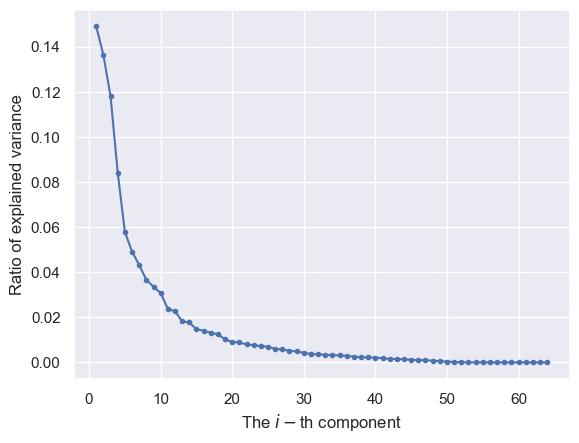

In [27]:
################# Your answer for Question 3.2   #################
pca_full = PCA().fit(data_digit.data)   # keep all 64 components
ratios = pca_full.explained_variance_ratio_


n_cols = 4
n_rows = int(np.ceil(len(ratios) / n_cols))

for row in range(n_rows):
    line = ""
    for col in range(n_cols):
        i = col * n_rows + row
        if i < len(ratios):
            line += f"PC{i + 1:>2}: {ratios[i]:.4f}    "
    print(line)



plt.plot(np.arange(1, len(ratios) + 1), ratios, marker='o', markersize=3)

plt.xlabel('The $i-$th component')
plt.ylabel('Ratio of explained variance')
################# Complete the code above #################

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

Text(0.5, 0.98, 'The eigen vector of each component')

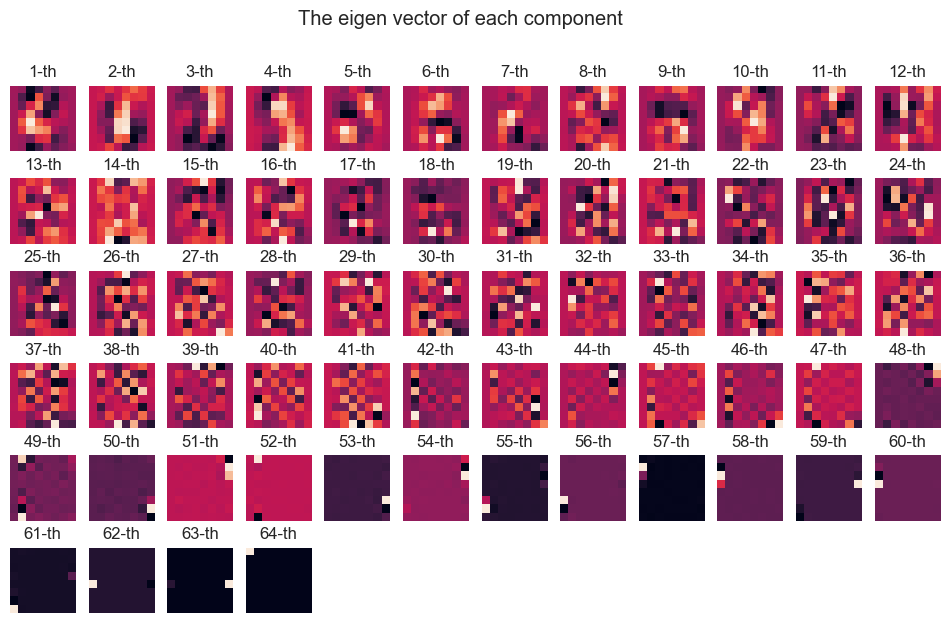

In [28]:
# Default # of components is the dimension of feature space 
pca = PCA()
pca.fit(data_digit.data)
h = 6
w = 12
fig, axes = plt.subplots(h, w)
fig.set_size_inches(12, 7)
for i in range(h):
    for j in range(w):
        idx = i * w + j
        if idx > 63:
            axes[i, j].axis('off')
        else:
            axes[i, j].imshow(pca.components_[idx].reshape(8, 8))
            axes[i, j].axis('off')
            axes[i, j].set_title(f'{idx + 1}-th')
fig.suptitle('The eigen vector of each component')

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

### Your solutions for Question 3.3:

The first thing I noticed was that the late eigenvectors don't have much information in them. They are a single pixel or few pixels and they are on the periphery. And conversely the high-ranking eigenvectors (those with large eigenvalues) are centered and have all of their information in the middle. This makes sense given that the digits that we are representing are in the middle of the images. Said differently, the early eigenvectors can really change the overall composition because they have a balance of pixels with high and pixels with low values.

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

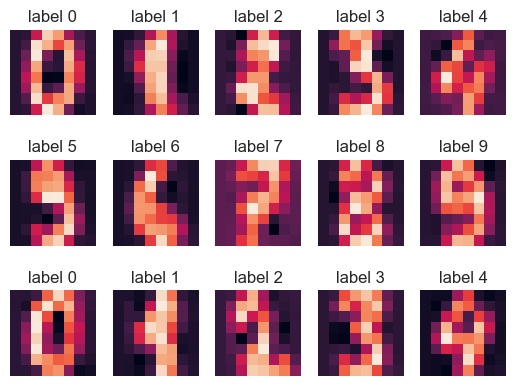

In [29]:
# Use pca from sklearn to fit on the feature space
pca_08 = PCA(0.8).fit(data_digit.data)

# Reconstruct 
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)

# Display the reconstructed images (with a much lower dimension)
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

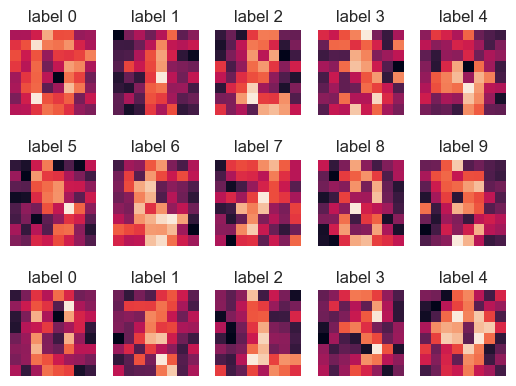

In [30]:
# Apply random noise on clean images
noisy_imgs = np.random.normal(data_digit.data, 5)
# Display the noisy images
display_digits(noisy_imgs)

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

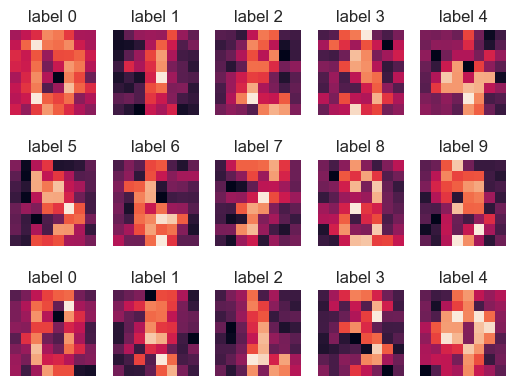

In [31]:
################# Your answer for Question 3.4   #################
# 1. Create a PCA model that keeps 80% of the variance
pca_noise = PCA(0.8)

# 2. Fit the model to the noisy images
pca_noise.fit(noisy_imgs)

# 3. Project the noisy images down to the lower-dimensional space
lower_dimension_noise = pca_noise.transform(noisy_imgs)

# 4. Map them back to 64 pixels
# name the reconstructed images from noisy images as 'reconstructed_noise'
reconstructed_noise = pca_noise.inverse_transform(lower_dimension_noise)

# Display the reconstructed images
display_digits(reconstructed_noise) 
################# Complete the code above #################


### Your written answers for Question 3.4:

If the noise in our dataset is low variance and the signal is high variance, then we can use PCA to separate the two. I think this really means not that the noise is less than the signal, but the signal can explain more of the data (or variance) in the top eigenvectors. This is like saying that the signal follows patterns or rules and those are the top eigenvectors. The noise, by comparison, is random, so it gets spread over all eigenvectors (presumably relatively evenly). If we had noise that was generated with someting less random than a normal distribution, then we may actually keep it in this process and PCA would be making the noise problem worse.